#EUR/USD Forex Trading Analysis & Prediction

##Part 1 — Financial Trading Analysis / Prediction

###Step 1 — Import Pandas

In [1]:
import pandas as pd

###Step 2 — Load the EURUSD data

In [2]:
df = pd.read_csv("EURUSD_FOREX.csv")

In [3]:
df

,Gmt time,Open,High,Low,Close,Volume
0,04.05.2003 00:00:00.000,1.12273,1.12338,1.12160,1.12169,2.570405e+05
1,05.05.2003 00:00:00.000,1.12161,1.13009,1.12014,1.12924,1.276006e+06
2,06.05.2003 00:00:00.000,1.12921,1.14506,1.12723,1.14234,1.281467e+06
3,07.05.2003 00:00:00.000,1.14218,1.14323,1.13265,1.13494,1.272597e+06
4,08.05.2003 00:00:00.000,1.13507,1.15077,1.13006,1.14820,1.266581e+06
...,...,...,...,...,...,...
7198,17.01.2023 00:00:00.000,1.08294,1.08693,1.07744,1.07893,4.897173e+05
7199,18.01.2023 00:00:00.000,1.07891,1.08873,1.07661,1.07972,3.651476e+05
7200,19.01.2023 00:00:00.000,1.07974,1.08398,1.07821,1.08333,2.114397e+05
7201,20.01.2023 00:00:00.000,1.08332,1.08587,1.08022,1.08549,1.565040e+05


In [4]:
df.head()

,Gmt time,Open,High,Low,Close,Volume
0,04.05.2003 00:00:00.000,1.12273,1.12338,1.12160,1.12169,257040.500
1,05.05.2003 00:00:00.000,1.12161,1.13009,1.12014,1.12924,1276005.625
2,06.05.2003 00:00:00.000,1.12921,1.14506,1.12723,1.14234,1281467.000
3,07.05.2003 00:00:00.000,1.14218,1.14323,1.13265,1.13494,1272596.625
4,08.05.2003 00:00:00.000,1.13507,1.15077,1.13006,1.14820,1266581.250


###Step 3 — Convert the date column

In [5]:
df['Gmt time'] = pd.to_datetime(
    df['Gmt time'],
    format="%d.%m.%Y %H:%M:%S.%f"
)

In [6]:
df.dtypes

,0
Gmt time,datetime64[ns]
Open,float64
High,float64
Low,float64
Close,float64
Volume,float64


In [34]:
df = df.set_index('Gmt time')

###Step 4 — Calculate Moving Average

In [7]:
df['MA'] = df["Close"].rolling(window=5).mean()

In [8]:
df

,Gmt time,Open,High,Low,Close,Volume,MA
0,2003-05-04,1.12273,1.12338,1.12160,1.12169,2.570405e+05,NaN
1,2003-05-05,1.12161,1.13009,1.12014,1.12924,1.276006e+06,NaN
2,2003-05-06,1.12921,1.14506,1.12723,1.14234,1.281467e+06,NaN
3,2003-05-07,1.14218,1.14323,1.13265,1.13494,1.272597e+06,NaN
4,2003-05-08,1.13507,1.15077,1.13006,1.14820,1.266581e+06,1.135282
...,...,...,...,...,...,...,...
7198,2023-01-17,1.08294,1.08693,1.07744,1.07893,4.897173e+05,1.082032
7199,2023-01-18,1.07891,1.08873,1.07661,1.07972,3.651476e+05,1.081372
7200,2023-01-19,1.07974,1.08398,1.07821,1.08333,2.114397e+05,1.081434
7201,2023-01-20,1.08332,1.08587,1.08022,1.08549,1.565040e+05,1.082082


<Axes: >

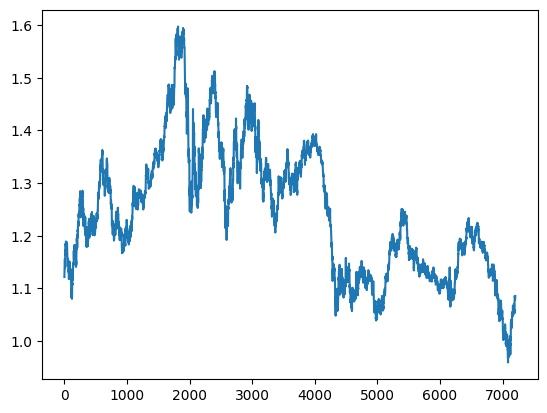

In [9]:
df.Close.plot()

###Step 5 — Identify the first candle after the weekend

In [10]:
df["isFirstMovement"] = [
    0
] + [
    1 if (df.Volume.iloc[i] > 0 and df.Volume.iloc[i-1] == 0)
    else 0
    for i in range(1, len(df))
]

In [11]:
df.head(20)

,Gmt time,Open,High,Low,Close,Volume,MA,isFirstMovement
0,2003-05-04,1.12273,1.12338,1.12160,1.12169,2.570405e+05,NaN,0
1,2003-05-05,1.12161,1.13009,1.12014,1.12924,1.276006e+06,NaN,0
2,2003-05-06,1.12921,1.14506,1.12723,1.14234,1.281467e+06,NaN,0
3,2003-05-07,1.14218,1.14323,1.13265,1.13494,1.272597e+06,NaN,0
4,2003-05-08,1.13507,1.15077,1.13006,1.14820,1.266581e+06,1.135282,0
5,2003-05-09,1.14831,1.15366,1.14346,1.14867,1.273339e+06,1.140678,0
6,2003-05-10,1.14867,1.14867,1.14867,1.14867,0.000000e+00,1.144564,0
7,2003-05-11,1.14870,1.15645,1.14867,1.15605,2.510314e+05,1.147306,1
8,2003-05-12,1.15632,1.16229,1.15225,1.15559,1.268231e+06,1.151436,0
9,2003-05-13,1.15544,1.15591,1.14620,1.15277,1.268299e+06,1.152350,0


In [12]:
df[df["isFirstMovement"] == 1]

,Gmt time,Open,High,Low,Close,Volume,MA,isFirstMovement
7,2003-05-11,1.14870,1.15645,1.14867,1.15605,251031.4063,1.147306,1
14,2003-05-18,1.15938,1.16841,1.15830,1.16576,257162.0000,1.154112,1
21,2003-05-25,1.18387,1.18402,1.18144,1.18177,258763.0938,1.176490,1
28,2003-06-01,1.17800,1.17813,1.17058,1.17203,261501.0000,1.178542,1
35,2003-06-08,1.16977,1.17102,1.16839,1.16989,258739.2031,1.171552,1
...,...,...,...,...,...,...,...,...
7168,2022-12-18,1.05895,1.05959,1.05824,1.05842,23419.3301,1.061324,1
7175,2022-12-25,1.06114,1.06237,1.06064,1.06191,4623.6499,1.061244,1
7182,2023-01-01,1.06970,1.07066,1.06788,1.07005,7410.3800,1.067892,1
7189,2023-01-08,1.06406,1.06628,1.06381,1.06627,14276.5400,1.061444,1


###Step 6 — Calculate the future trend

In [13]:
rollw = 4

df["FutureRollingAverage"] = (
    df.Close.rolling(rollw).mean().shift(-rollw+1)
)

In [14]:
df.head()

,Gmt time,Open,High,Low,Close,Volume,MA,isFirstMovement,FutureRollingAverage
0,2003-05-04,1.12273,1.12338,1.12160,1.12169,257040.500,NaN,0,1.132052
1,2003-05-05,1.12161,1.13009,1.12014,1.12924,1276005.625,NaN,0,1.138680
2,2003-05-06,1.12921,1.14506,1.12723,1.14234,1281467.000,NaN,0,1.143537
3,2003-05-07,1.14218,1.14323,1.13265,1.13494,1272596.625,NaN,0,1.145120
4,2003-05-08,1.13507,1.15077,1.13006,1.14820,1266581.250,1.135282,0,1.150397


###Step 7 — Create FutureTrend

In [15]:
df["FutureTrend"] = [
    2 if df.FutureRollingAverage.iloc[i] > df.Close.iloc[i]
    else 1 if df.FutureRollingAverage.iloc[i] < df.Close.iloc[i]
    else 0
    for i in range(len(df))
]

In [16]:
df.FutureTrend.value_counts()

,count
FutureTrend,
2,3624
1,3574
0,5


###Step 8 — Determine current candle direction

In [17]:
df["CandleDirection"] = [
    2 if df.iloc[i].Close > df.iloc[i].Open
    else 1 if df.iloc[i].Close < df.iloc[i].Open
    else 0
    for i in range(len(df))
]

###Step 9 — Check whether the first candle predicted the future trend

In [18]:
correct_predictions = len(
    df[
        (df.CandleDirection != 0) &
        (df.FutureTrend == df.CandleDirection) &
        (df.isFirstMovement == 1)
    ]
)

incorrect_predictions = len(
    df[
        (df.CandleDirection != 0) &
        (df.FutureTrend != df.CandleDirection) &
        (df.isFirstMovement == 1)
    ]
)

In [19]:
print(
    correct_predictions,
    incorrect_predictions,
    correct_predictions / (correct_predictions + incorrect_predictions)
)

502 523 0.4897560975609756


##Part 2 — Engulfing Candles

###Step 10 — Detect Engulfing Candles

In [20]:
def isEngulfing(l):
    if (
        df.iloc[l].Open < min(df.iloc[l-1].Open, df.iloc[l-1].Close)
        and
        df.iloc[l].Close > max(df.iloc[l-1].Open, df.iloc[l-1].Close)
        and
        df.iloc[l-1].Open > df.iloc[l-1].Close
    ):
        return 2

    elif (
        df.iloc[l].Open > max(df.iloc[l-1].Open, df.iloc[l-1].Close)
        and
        df.iloc[l].Close < min(df.iloc[l-1].Open, df.iloc[l-1].Close)
        and
        df.iloc[l-1].Open < df.iloc[l-1].Close
    ):
        return 1

    else:
        return 0

In [21]:
df["isEngulfing"] = [
    0
] + [
    isEngulfing(idx)
    for idx in range(1, len(df))
]

###Step 11 — Understand the values

In [22]:
df.isEngulfing.value_counts()

,count
isEngulfing,
0,6677
1,264
2,262


###Step 12 — Determine whether the engulfing pattern was predictive

In [23]:
def isPredictable(l):
    if df.iloc[l-1].isEngulfing == df.iloc[l].CandleDirection:
        return df.iloc[l].CandleDirection

    elif df.iloc[l-1].isEngulfing != 0:
        return 3

    else:
        return 0

In [24]:
df["isPredictable"] = [
    0
] + [
    isPredictable(idx)
    for idx in range(1, len(df))
]

In [25]:
df.isPredictable.value_counts()

,count
isPredictable,
0,6677
3,302
1,113
2,111


###Step 13 — Calculate the future price change

In [26]:
df["FuturePriceChange"] = (
    df["Close"].shift(-4) - df["Close"]
)

In [27]:
df[["Close", "isEngulfing", "FuturePriceChange"]].head(20)

,Close,isEngulfing,FuturePriceChange
0,1.12169,0,0.02651
1,1.12924,2,0.01943
2,1.14234,0,0.00633
3,1.13494,0,0.02111
4,1.14820,0,0.00739
5,1.14867,0,0.00410
6,1.14867,0,-0.00097
7,1.15605,0,-0.01767
8,1.15559,0,0.00377
9,1.15277,0,0.00659


###Step 14 — Calculate average future price change for engulfing candles

In [28]:
df[df["isEngulfing"] == 1]["FuturePriceChange"].mean()

np.float64(-0.0018376136363636348)

In [29]:
df[df["isEngulfing"] == 2]["FuturePriceChange"].mean()

np.float64(0.0008549236641221379)

###Step 15 — Calculate percentage change

In [30]:
df["FuturePriceChangePct"] = (
    (df["Close"].shift(-4) / df["Close"]) - 1
) * 100

In [31]:
print(
    "Bearish engulfing average:",
    df[df["isEngulfing"] == 1]["FuturePriceChangePct"].mean()
)

print(
    "Bullish engulfing average:",
    df[df["isEngulfing"] == 2]["FuturePriceChangePct"].mean()
)

Bearish engulfing average: -0.14283601174987218
Bullish engulfing average: 0.08090510243799225


###Step 16 — Count predictable engulfing patterns

In [32]:
predictable = len(
    df[df["isPredictable"].isin([1, 2])]
)

not_predictable = len(
    df[df["isPredictable"] == 3]
)

print("Predictable:", predictable)
print("Not predictable:", not_predictable)

Predictable: 224
Not predictable: 302


In [33]:
accuracy = predictable / (predictable + not_predictable)

print(accuracy)

0.42585551330798477


##Part 3 — Candlestick Trend Visualization

###Step 17 — Import the visualization libraries

In [35]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

###Step 18 — Select data for visualization

In [36]:
plot_df = df.iloc[0:40].copy()

plot_df.head()

,Open,High,Low,Close,Volume,MA,isFirstMovement,FutureRollingAverage,FutureTrend,CandleDirection,isEngulfing,isPredictable,FuturePriceChange,FuturePriceChangePct
Gmt time,,,,,,,,,,,,,,
2003-05-04,1.12273,1.12338,1.12160,1.12169,257040.500,NaN,0,1.132052,2,1,0,0,0.02651,2.363398
2003-05-05,1.12161,1.13009,1.12014,1.12924,1276005.625,NaN,0,1.138680,2,2,2,0,0.01943,1.720626
2003-05-06,1.12921,1.14506,1.12723,1.14234,1281467.000,NaN,0,1.143537,2,2,0,2,0.00633,0.554126
2003-05-07,1.14218,1.14323,1.13265,1.13494,1272596.625,NaN,0,1.145120,2,1,0,0,0.02111,1.860010
2003-05-08,1.13507,1.15077,1.13006,1.14820,1266581.250,1.135282,0,1.150397,2,2,0,0,0.00739,0.643616


In [37]:
df.iloc[0:40]

,Open,High,Low,Close,Volume,MA,isFirstMovement,FutureRollingAverage,FutureTrend,CandleDirection,isEngulfing,isPredictable,FuturePriceChange,FuturePriceChangePct
Gmt time,,,,,,,,,,,,,,
2003-05-04,1.12273,1.12338,1.12160,1.12169,2.570405e+05,NaN,0,1.132052,2,1,0,0,0.02651,2.363398
2003-05-05,1.12161,1.13009,1.12014,1.12924,1.276006e+06,NaN,0,1.138680,2,2,2,0,0.01943,1.720626
2003-05-06,1.12921,1.14506,1.12723,1.14234,1.281467e+06,NaN,0,1.143537,2,2,0,2,0.00633,0.554126
2003-05-07,1.14218,1.14323,1.13265,1.13494,1.272597e+06,NaN,0,1.145120,2,1,0,0,0.02111,1.860010
2003-05-08,1.13507,1.15077,1.13006,1.14820,1.266581e+06,1.135282,0,1.150397,2,2,0,0,0.00739,0.643616
2003-05-09,1.14831,1.15366,1.14346,1.14867,1.273339e+06,1.140678,0,1.152245,2,2,0,0,0.00410,0.356935
2003-05-10,1.14867,1.14867,1.14867,1.14867,0.000000e+00,1.144564,0,1.153270,2,0,0,0,-0.00097,-0.084445
2003-05-11,1.14870,1.15645,1.14867,1.15605,2.510314e+05,1.147306,1,1.153027,1,2,0,0,-0.01767,-1.528481
2003-05-12,1.15632,1.16229,1.15225,1.15559,1.268231e+06,1.151436,0,1.148610,1,1,0,0,0.00377,0.326240


In [38]:
df.iloc[100:140]

,Open,High,Low,Close,Volume,MA,isFirstMovement,FutureRollingAverage,FutureTrend,CandleDirection,isEngulfing,isPredictable,FuturePriceChange,FuturePriceChangePct
Gmt time,,,,,,,,,,,,,,
2003-08-12,1.13535,1.13709,1.12659,1.12727,1.340615e+06,1.130860,0,1.127668,2,1,0,0,-0.00130,-0.115323
2003-08-13,1.12724,1.13302,1.12169,1.13093,1.352524e+06,1.130940,0,1.127342,1,2,0,0,-0.00479,-0.423545
2003-08-14,1.13097,1.13365,1.12234,1.12650,1.335925e+06,1.130134,0,1.126145,1,1,1,0,-0.01268,-1.125610
2003-08-15,1.12629,1.12868,1.12396,1.12597,1.234156e+06,1.129222,0,1.122975,1,1,0,1,-0.01304,-1.158113
2003-08-16,1.12597,1.12597,1.12597,1.12597,0.000000e+00,1.127328,0,1.119715,1,0,0,0,-0.01513,-1.343730
2003-08-17,1.12525,1.13219,1.12337,1.12614,8.336600e+04,1.127102,1,1.115932,1,2,0,0,-0.03319,-2.947236
2003-08-18,1.12601,1.12672,1.11221,1.11382,1.353761e+06,1.123680,0,1.107635,1,1,0,0,-0.02537,-2.277747
2003-08-19,1.11377,1.11470,1.10534,1.11293,1.338474e+06,1.120966,0,1.101293,1,1,0,0,-0.02448,-2.199599
2003-08-20,1.11277,1.11397,1.10783,1.11084,1.347232e+06,1.117940,0,1.095172,1,1,0,0,-0.02533,-2.280256


In [39]:
df.iloc[500:540]

,Open,High,Low,Close,Volume,MA,isFirstMovement,FutureRollingAverage,FutureTrend,CandleDirection,isEngulfing,isPredictable,FuturePriceChange,FuturePriceChangePct
Gmt time,,,,,,,,,,,,,,
2004-09-15,1.22477,1.22593,1.21323,1.21463,1.343743e+06,1.224150,0,1.217455,2,1,0,0,0.00191,0.157250
2004-09-16,1.21455,1.21971,1.21192,1.21835,1.348453e+06,1.222492,0,1.217933,1,2,0,0,-0.00115,-0.094390
2004-09-17,1.21830,1.22215,1.21555,1.21842,1.278557e+06,1.220528,0,1.217645,1,2,0,0,0.01393,1.143284
2004-09-18,1.21842,1.21842,1.21842,1.21842,0.000000e+00,1.218926,0,1.221128,2,0,0,0,0.00815,0.668899
2004-09-19,1.21749,1.21840,1.21576,1.21654,9.361500e+04,1.217272,1,1.223165,2,1,0,0,0.01102,0.905848
2004-09-20,1.21647,1.21784,1.21212,1.21720,1.337796e+06,1.217786,0,1.225920,2,2,0,0,0.00994,0.816628
2004-09-21,1.21699,1.23459,1.21663,1.23235,1.346430e+06,1.220586,0,1.228405,1,2,0,0,-0.00521,-0.422770
2004-09-22,1.23236,1.23297,1.22277,1.22657,1.352816e+06,1.222216,0,1.227102,2,1,0,0,0.00094,0.076636
2004-09-23,1.22664,1.23320,1.22514,1.22756,1.342273e+06,1.224044,0,1.227337,1,2,0,0,0.00243,0.197954


###Step 19 — Create the figure

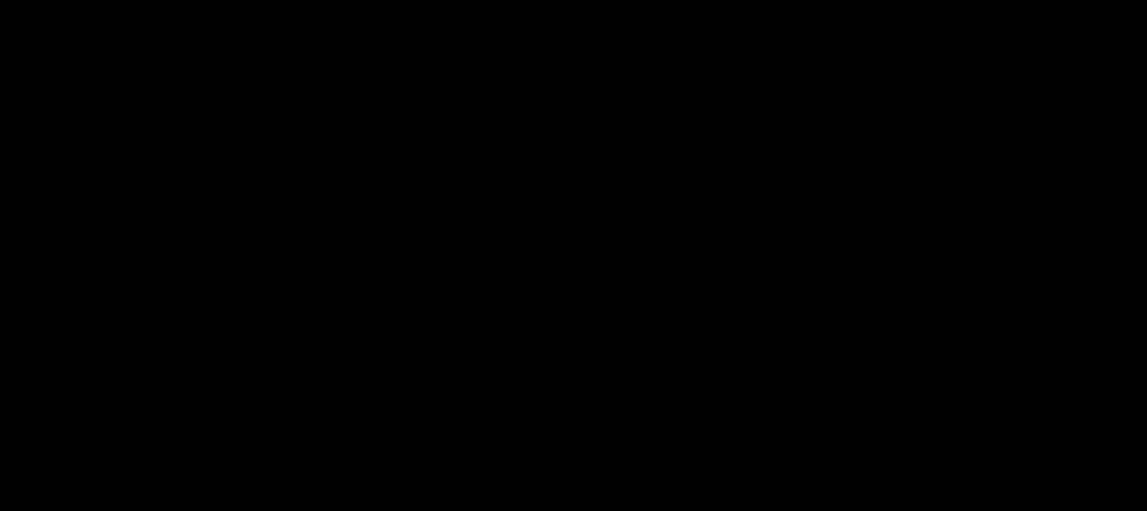

In [40]:
fig, ax = plt.subplots(figsize=(14, 6))

fig.patch.set_facecolor("black")
ax.set_facecolor("black")

###Step 20 — Create the candlesticks

In [41]:
for i, row in enumerate(plot_df.itertuples()):

    open_price = row.Open
    close_price = row.Close
    high_price = row.High
    low_price = row.Low

    # Candle direction
    if close_price >= open_price:
        body_color = "lime"
    else:
        body_color = "white"

    # High-Low wick
    ax.plot(
        [i, i],
        [low_price, high_price],
        color=body_color,
        linewidth=1
    )

    # Candle body
    body_bottom = min(open_price, close_price)
    body_height = abs(close_price - open_price)

    if body_height == 0:
        body_height = 0.00001

    candle = Rectangle(
        (i - 0.3, body_bottom),
        0.6,
        body_height,
        facecolor=body_color,
        edgecolor="lime",
        linewidth=1
    )

    ax.add_patch(candle)

###Step 21 — Add the Bearish label

In [42]:
ax.annotate(
    "down / Bearish",
    xy=(2, plot_df.iloc[2].High),
    xytext=(5, plot_df.High.max()),
    color="red",
    fontsize=18,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=2
    )
)

Text(5, 1.19286, 'down / Bearish')

###Step 22 — Add the bearish trend arrow

In [43]:
ax.annotate(
    "trend",
    xy=(18, plot_df.iloc[18].Low),
    xytext=(4, plot_df.Low.min()),
    color="orange",
    fontsize=18,
    arrowprops=dict(
        arrowstyle="->",
        color="orange",
        lw=2
    )
)

Text(4, 1.12014, 'trend')

###Step 23 — Add the Bullish label

In [44]:
ax.annotate(
    "up / Bullish",
    xy=(25, plot_df.iloc[25].Low),
    xytext=(27, plot_df.Low.min()),
    color="red",
    fontsize=18,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=2
    )
)

Text(27, 1.12014, 'up / Bullish')

###Step 24 — Add the bullish trend arrow

In [45]:
ax.annotate(
    "trend",
    xy=(38, plot_df.iloc[38].High),
    xytext=(28, plot_df.High.max()),
    color="orange",
    fontsize=18,
    arrowprops=dict(
        arrowstyle="->",
        color="orange",
        lw=2
    )
)

Text(28, 1.19286, 'trend')

###Step 25 — Remove the axes

In [46]:
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

###Step 26 —  complete the candlestrick visual

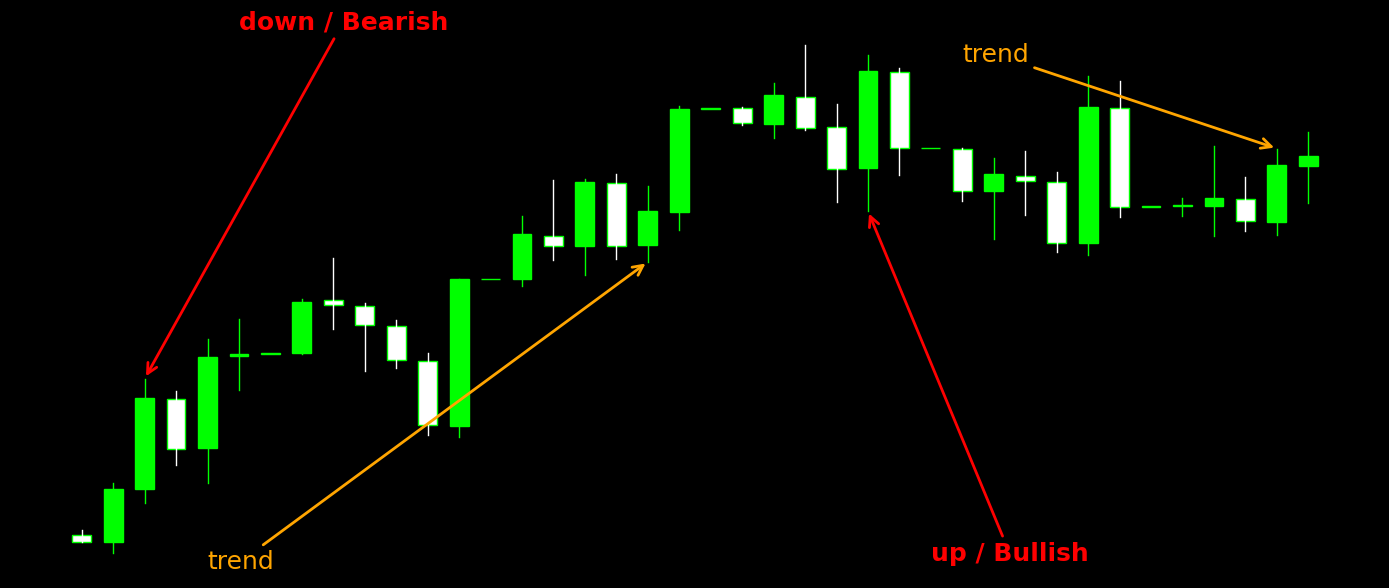

In [47]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Select a small portion of the data
plot_df = df.iloc[0:40].copy()

# Create figure
fig, ax = plt.subplots(figsize=(14, 6))

# Black background
fig.patch.set_facecolor("black")
ax.set_facecolor("black")

# Plot candlesticks
for i, row in enumerate(plot_df.itertuples()):

    open_price = row.Open
    close_price = row.Close
    high_price = row.High
    low_price = row.Low

    # Bullish candle
    if close_price >= open_price:
        body_color = "lime"
    else:
        # Bearish candle
        body_color = "white"

    # Wick
    ax.plot(
        [i, i],
        [low_price, high_price],
        color=body_color,
        linewidth=1
    )

    # Candle body
    body_bottom = min(open_price, close_price)
    body_height = abs(close_price - open_price)

    if body_height == 0:
        body_height = 0.00001

    candle = Rectangle(
        (i - 0.3, body_bottom),
        0.6,
        body_height,
        facecolor=body_color,
        edgecolor="lime",
        linewidth=1
    )

    ax.add_patch(candle)


# -----------------------------
# Bearish trend annotation
# -----------------------------

ax.annotate(
    "down / Bearish",
    xy=(2, plot_df.iloc[2].High),
    xytext=(5, plot_df.High.max() * 1.002),
    color="red",
    fontsize=18,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=2
    )
)

ax.annotate(
    "trend",
    xy=(18, plot_df.iloc[18].Low),
    xytext=(4, plot_df.Low.min() * 0.998),
    color="orange",
    fontsize=18,
    arrowprops=dict(
        arrowstyle="->",
        color="orange",
        lw=2
    )
)


# -----------------------------
# Bullish trend annotation
# -----------------------------

ax.annotate(
    "up / Bullish",
    xy=(25, plot_df.iloc[25].Low),
    xytext=(27, plot_df.Low.min() * 0.999),
    color="red",
    fontsize=18,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=2
    )
)

ax.annotate(
    "trend",
    xy=(38, plot_df.iloc[38].High),
    xytext=(28, plot_df.High.max() * 0.998),
    color="orange",
    fontsize=18,
    arrowprops=dict(
        arrowstyle="->",
        color="orange",
        lw=2
    )
)


# Remove axes
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()